In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import PoissonRegressor
import pandas as pd
from sklearn.metrics import mean_poisson_deviance, mean_squared_error
from sklearn.model_selection import cross_val_score, KFold
import matplotlib.pyplot as plt
import numpy as np

# Data Preprocessing

Split features and target variables.

In [3]:
raw_df = pd.read_csv("telematics_syn-032021.csv")
print(f"Length of raw_df: {len(raw_df)}")
# print(f"Minimum Insured.age: {min(raw_df['Insured.age'])}")
# Drop rows where Insured.age - Years.noclaims < 16, as these are likely data entry errors
clean_df = raw_df[raw_df["Insured.age"] - raw_df["Years.noclaims"] >= 16].copy()
print(f"Length of clean_df after dropping rows with unexpected years of no claims: {len(clean_df)}")

# convert the "Territory" column to a categorical type for VIF calculation
clean_df["Territory"] = clean_df["Territory"].astype("category")

X = clean_df.drop(columns=['NB_Claim', 'AMT_Claim', 'Duration'])
# Remove redundant columns that are highly correlated with other features
X = X.drop(columns=['Pct.drive.sun', 'Pct.drive.wkday', 'Pct.drive.wkend'])
y_num = clean_df['NB_Claim']
y_amt = clean_df['AMT_Claim']
exposure = clean_df['Duration']/366  # Convert exposure to years


print(f"Clean_df shape: {clean_df.shape}")
print(f"X shape: {X.shape}")

Length of raw_df: 100000
Length of clean_df after dropping rows with unexpected years of no claims: 98541
Clean_df shape: (98541, 52)
X shape: (98541, 46)


Split features into categories.

In [4]:
traditional_features = X[['Insured.age', 'Insured.sex', 'Car.age', 'Marital',
       'Car.use', 'Credit.score', 'Region', 'Annual.miles.drive',
       'Years.noclaims', 'Territory']]
telematics_features = X.drop(columns=traditional_features)

A quick check to ensure no columns are left out.

In [5]:
assert len(traditional_features.columns) + len(telematics_features.columns) == len(X.columns), "Feature split does not match original feature count"

Check what encoder I should used based on the categorical data.

In [6]:
traditional_cat_columns = traditional_features.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Traditional categorical features: {traditional_cat_columns}")
for col in traditional_cat_columns:
    print(col, traditional_features[col].unique())

Traditional categorical features: ['Insured.sex', 'Marital', 'Car.use', 'Region', 'Territory']
Insured.sex ['Male' 'Female']
Marital ['Married' 'Single']
Car.use ['Commute' 'Private' 'Commercial' 'Farmer']
Region ['Urban' 'Rural']
Territory [70, 26, 84, 30, 43, ..., 75, 82, 91, 60, 11]
Length: 55
Categories (55, int64): [11, 12, 13, 14, ..., 88, 89, 90, 91]


## Traditional Features

In [7]:
X_train, X_test, y_train, y_test, exposure_train, exposure_test = train_test_split(traditional_features, y_num, exposure, test_size=0.2, random_state=42, stratify=y_num)

Given that the categorical variable above consists of categories without any inherent order or ranking. I decided to use one-hot encoder.

In [8]:
ct = ColumnTransformer(
    transformers=[("ohe", OneHotEncoder(drop="first", sparse_output=False), traditional_cat_columns)],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

In [9]:
# Scale every column (including the one-hot dummies), not just the numeric ones.
# This matters once alpha > 0: regularization penalizes coefficient magnitude
# directly, so leaving dummies on a raw 0/1 scale would penalize them unevenly
# relative to the standardized continuous features.
scaler = StandardScaler().set_output(transform="pandas")
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
print(X_train.shape, X_test.shape)
print(list(X_train.columns) == list(X_test.columns))

(78832, 65) (19709, 65)
True


In [11]:
def poisson_cv_scores(X, y_num, exposure, n_splits=5, alpha=0.0, random_state=42):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    d2_scores = []
    deviance_scores = []
    for train_idx, val_idx in kf.split(X):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y_num.iloc[train_idx], y_num.iloc[val_idx]
        exp_tr, exp_val = exposure.iloc[train_idx], exposure.iloc[val_idx]

        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_val = scaler.transform(X_val)

        model = PoissonRegressor(alpha=alpha)
        model.fit(X_tr, y_tr / exp_tr, sample_weight=exp_tr)

        y_val_pred = model.predict(X_val)
        d2_scores.append(model.score(X_val, y_val / exp_val, sample_weight=exp_val))
        deviance_scores.append(mean_poisson_deviance(y_val / exp_val, y_val_pred, sample_weight=exp_val))
    return np.array(d2_scores), np.array(deviance_scores)

In [12]:
cv_d2_scores, cv_deviance_scores = poisson_cv_scores(X_train, y_train, exposure_train, n_splits=5, alpha=0.0, random_state=42)
cv_d2_scores, cv_deviance_scores

(array([0.03258315, 0.04156898, 0.03517716, 0.03533775, 0.03094059]),
 array([0.31118585, 0.31535745, 0.31548007, 0.30861926, 0.31209819]))

In [13]:
print(f"Mean D2: {np.mean(cv_d2_scores):.4f}")
print(f"Standard deviation of D2: {np.std(cv_d2_scores):.4f}")
print(f"95% range of D2: {np.quantile(cv_d2_scores, [0.025, 0.975])}")
print()
print(f"Mean Poisson deviance: {np.mean(cv_deviance_scores):.4f}")
print(f"Standard deviation of Poisson deviance: {np.std(cv_deviance_scores):.4f}")
print(f"95% range of Poisson deviance: {np.quantile(cv_deviance_scores, [0.025, 0.975])}")

Mean D2: 0.0351
Standard deviation of D2: 0.0036
95% range of D2: [0.03110485 0.04094586]

Mean Poisson deviance: 0.3125
Standard deviation of Poisson deviance: 0.0026
95% range of Poisson deviance: [0.30887592 0.31546781]


In [14]:
alphas = np.logspace(-4, 2, 13)
alpha_cv_results = []
for alpha in alphas:
    d2_scores, deviance_scores = poisson_cv_scores(
        X_train, y_train, exposure_train, n_splits=5, alpha=alpha, random_state=42
    )
    alpha_cv_results.append({
        "alpha": alpha,
        "mean_d2": d2_scores.mean(),
        "mean_deviance": deviance_scores.mean(),
    })

alpha_cv_df = pd.DataFrame(alpha_cv_results)
print(alpha_cv_df)

best_alpha = alpha_cv_df.loc[alpha_cv_df["mean_deviance"].idxmin(), "alpha"]
print(f"\nBest alpha (lowest mean CV deviance): {best_alpha}")

         alpha   mean_d2  mean_deviance
0     0.000100  0.035124       0.312547
1     0.000316  0.035158       0.312536
2     0.001000  0.035261       0.312503
3     0.003162  0.035413       0.312455
4     0.010000  0.035406       0.312458
5     0.031623  0.033179       0.313181
6     0.100000  0.025297       0.315737
7     0.316228  0.014119       0.319360
8     1.000000  0.005902       0.322022
9     3.162278  0.002053       0.323269
10   10.000000  0.000644       0.323726
11   31.622777  0.000175       0.323878
12  100.000000  0.000024       0.323927

Best alpha (lowest mean CV deviance): 0.0031622776601683794


Work done for understanding the data for traditional model

In [15]:
model = PoissonRegressor(alpha=best_alpha)
model.fit(X_train, y_train/exposure_train, sample_weight=exposure_train)
y_pred = model.predict(X_test)
model_score = model.score(X_test, y_test/exposure_test, sample_weight=exposure_test)
print(f"Model score: {model_score}")
print(f"predicted claims: {(y_pred)[:5]}")
coef_pairs = sorted(zip(X_train.columns, model.coef_), key=lambda pair: abs(pair[1]), reverse=True)
print(f"Model coefficients (sorted by abs value desc): {[(col, f'{np.float64(coef):.6f}') for col, coef in coef_pairs]}")
print(f"Number of iterations: {model.n_iter_}")   # how many iterations it actually ran

Model score: 0.01984297587270767
predicted claims: [0.04638517 0.03180773 0.06309538 0.06186997 0.04404006]
Model coefficients (sorted by abs value desc): [('Car.age', '-0.280658'), ('Credit.score', '-0.238812'), ('Years.noclaims', '-0.133384'), ('Annual.miles.drive', '0.110194'), ('Car.use_Farmer', '-0.074376'), ('Region_Urban', '0.057102'), ('Car.use_Commute', '-0.045130'), ('Car.use_Private', '-0.044119'), ('Territory_89', '-0.041452'), ('Territory_54', '0.039185'), ('Territory_85', '-0.038361'), ('Territory_57', '0.031548'), ('Territory_76', '0.030746'), ('Territory_71', '0.029603'), ('Territory_12', '-0.028133'), ('Territory_24', '-0.026040'), ('Territory_86', '-0.024439'), ('Territory_69', '0.024051'), ('Territory_67', '-0.023585'), ('Territory_81', '-0.023404'), ('Territory_83', '0.023329'), ('Territory_90', '-0.023281'), ('Territory_87', '-0.023254'), ('Territory_33', '0.023116'), ('Territory_77', '0.022541'), ('Territory_65', '-0.022294'), ('Territory_26', '0.021913'), ('Terri

In [16]:
coef_pairs

[('Car.age', np.float64(-0.2806578560405119)),
 ('Credit.score', np.float64(-0.2388121295719334)),
 ('Years.noclaims', np.float64(-0.13338442658685326)),
 ('Annual.miles.drive', np.float64(0.11019384207910876)),
 ('Car.use_Farmer', np.float64(-0.07437594077767357)),
 ('Region_Urban', np.float64(0.0571023153007772)),
 ('Car.use_Commute', np.float64(-0.04513045023555184)),
 ('Car.use_Private', np.float64(-0.04411913691847412)),
 ('Territory_89', np.float64(-0.041452399637179324)),
 ('Territory_54', np.float64(0.03918512356129147)),
 ('Territory_85', np.float64(-0.038360778318122596)),
 ('Territory_57', np.float64(0.03154767964937802)),
 ('Territory_76', np.float64(0.030746354322156718)),
 ('Territory_71', np.float64(0.029603274731787293)),
 ('Territory_12', np.float64(-0.028133095406774965)),
 ('Territory_24', np.float64(-0.026040307659540053)),
 ('Territory_86', np.float64(-0.024438822999903846)),
 ('Territory_69', np.float64(0.02405059714538666)),
 ('Territory_67', np.float64(-0.023584

In [17]:
deviance = mean_poisson_deviance(
    y_test / exposure_test,  
    y_pred,                  
    sample_weight=exposure_test
)

mse = mean_squared_error(
    y_test / exposure_test,   
    y_pred,                  
    sample_weight=exposure_test
)
print(f"Mean Poisson deviance: {deviance}")
print(f"Mean squared error: {mse}")

Mean Poisson deviance: 0.3182291474928741
Mean squared error: 0.0607233431509853


/var/folders/v_/3rx_jnys7wb2_zt50m4fwqzh0000gn/T/ipykernel_87422/1067792725.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  lift = results.groupby("bucket").apply(


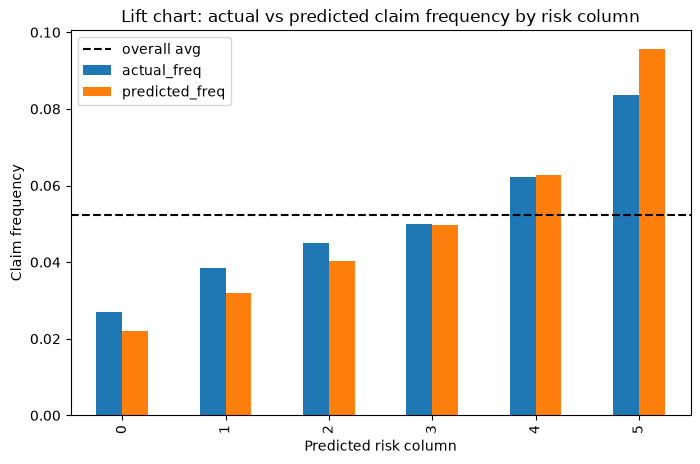

In [18]:
results = pd.DataFrame({
    "predicted_rate": y_pred,           
    "actual_claims": y_test.values,     
    "exposure": exposure_test.values 
})

# sort everyone into risk buckets, based on predicted risk
results["bucket"] = pd.qcut(results["predicted_rate"].rank(method="first"), 6, labels=False)

# for each bucket, compare actual vs predicted claim frequency (exposure-weighted)
lift = results.groupby("bucket").apply(
    lambda g: pd.Series({
        "actual_freq": g["actual_claims"].sum() / g["exposure"].sum(),
        "predicted_freq": (g["predicted_rate"] * g["exposure"]).sum() / g["exposure"].sum(),
    })
)
overall_freq = results["actual_claims"].sum() / results["exposure"].sum()

# plot actual vs predicted frequency across deciles, ordered low risk -> high risk
ax = lift.plot(kind="bar", figsize=(8, 5))
ax.axhline(overall_freq, color="black", linestyle="--", label="overall avg")
ax.set_xlabel("Predicted risk column")
ax.set_ylabel("Claim frequency")
ax.set_title("Lift chart: actual vs predicted claim frequency by risk column")
ax.legend()
plt.show()

## Pure telematics

In [19]:
X_train, X_test, y_train, y_test, exposure_train, exposure_test = train_test_split(
    telematics_features, y_num, exposure, test_size=0.2, random_state=42, stratify=y_num
)
scaler = StandardScaler().set_output(transform="pandas")
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

cv_d2_scores, cv_deviance_scores = poisson_cv_scores(X_train, y_train, exposure_train, n_splits=5, alpha=0.0, random_state=42)
cv_d2_scores, cv_deviance_scores

(array([0.10855432, 0.11722759, 0.12589194, 0.1117815 , 0.13307395]),
 array([0.28674845, 0.29046311, 0.28581793, 0.28416302, 0.27920482]))

In [20]:
print(f"Mean D2: {np.mean(cv_d2_scores):.4f}")
print(f"Standard deviation of D2: {np.std(cv_d2_scores):.4f}")
print(f"95% range of D2: {np.quantile(cv_d2_scores, [0.025, 0.975])}")
print()
print(f"Mean Poisson deviance: {np.mean(cv_deviance_scores):.4f}")
print(f"Standard deviation of Poisson deviance: {np.std(cv_deviance_scores):.4f}")
print(f"95% range of Poisson deviance: {np.quantile(cv_deviance_scores, [0.025, 0.975])}")

Mean D2: 0.1193
Standard deviation of D2: 0.0090
95% range of D2: [0.10887704 0.13235575]

Mean Poisson deviance: 0.2853
Standard deviation of Poisson deviance: 0.0037
95% range of Poisson deviance: [0.27970064 0.29009164]


In [21]:
alphas = np.logspace(-4, 2, 13)
alpha_cv_results = []
for alpha in alphas:
    d2_scores, deviance_scores = poisson_cv_scores(
        X_train, y_train, exposure_train, n_splits=5, alpha=alpha, random_state=42
    )
    alpha_cv_results.append({
        "alpha": alpha,
        "mean_d2": d2_scores.mean(),
        "mean_deviance": deviance_scores.mean(),
    })

alpha_cv_df = pd.DataFrame(alpha_cv_results)
print(alpha_cv_df)

best_alpha = alpha_cv_df.loc[alpha_cv_df["mean_deviance"].idxmin(), "alpha"]
print(f"\nBest alpha (lowest mean CV deviance): {best_alpha}")

         alpha   mean_d2  mean_deviance
0     0.000100  0.119710       0.285148
1     0.000316  0.119745       0.285137
2     0.001000  0.119637       0.285172
3     0.003162  0.119307       0.285279
4     0.010000  0.117448       0.285880
5     0.031623  0.109651       0.288407
6     0.100000  0.087511       0.295582
7     0.316228  0.050242       0.307658
8     1.000000  0.020798       0.317197
9     3.162278  0.007232       0.321591
10   10.000000  0.002334       0.323178
11   31.622777  0.000715       0.323703
12  100.000000  0.000195       0.323871

Best alpha (lowest mean CV deviance): 0.00031622776601683794


In [22]:
model = PoissonRegressor(alpha=best_alpha)
model.fit(X_train, y_train/exposure_train, sample_weight=exposure_train)
y_pred = model.predict(X_test)
model_score = model.score(X_test, y_test/exposure_test, sample_weight=exposure_test)
print(f"Model score: {model_score}")
print(f"predicted claims: {(y_pred)[:5]}")
coef_pairs = sorted(zip(X_train.columns, model.coef_), key=lambda pair: abs(pair[1]), reverse=True)
print(f"Model coefficients (sorted by abs value desc): {[(col, f'{np.float64(coef):.6f}') for col, coef in coef_pairs]}")
print(f"Number of iterations: {model.n_iter_}")   # how many iterations it actually ran

Model score: 0.12928755757061772
predicted claims: [0.01614943 0.01977728 0.02820861 0.06935803 0.01797734]
Model coefficients (sorted by abs value desc): [('Annual.pct.driven', '0.566168'), ('Total.miles.driven', '0.247622'), ('Brake.06miles', '0.178575'), ('Pct.drive.thr', '0.171408'), ('Avgdays.week', '0.165390'), ('Pct.drive.rush am', '-0.165251'), ('Pct.drive.2hrs', '0.138209'), ('Pct.drive.mon', '0.134834'), ('Pct.drive.tue', '0.107185'), ('Right.turn.intensity11', '0.101168'), ('Pct.drive.fri', '0.096194'), ('Accel.06miles', '0.092328'), ('Pct.drive.4hrs', '-0.087521'), ('Right.turn.intensity12', '-0.086383'), ('Left.turn.intensity08', '0.083500'), ('Right.turn.intensity10', '0.079334'), ('Left.turn.intensity10', '-0.073696'), ('Brake.08miles', '0.073552'), ('Right.turn.intensity08', '-0.072446'), ('Accel.09miles', '-0.072136'), ('Pct.drive.sat', '0.066639'), ('Pct.drive.rush pm', '0.065432'), ('Left.turn.intensity12', '0.050529'), ('Pct.drive.wed', '0.050477'), ('Brake.14miles'

In [23]:
deviance = mean_poisson_deviance(
    y_test / exposure_test,  
    y_pred,                  
    sample_weight=exposure_test
)

mse = mean_squared_error(
    y_test / exposure_test,   
    y_pred,                  
    sample_weight=exposure_test
)
print(f"Mean Poisson deviance: {deviance}")
print(f"Mean squared error: {mse}")

Mean Poisson deviance: 0.28269560024063606
Mean squared error: 0.06069732815193338


In [24]:
coef_pairs

[('Annual.pct.driven', np.float64(0.5661683550439872)),
 ('Total.miles.driven', np.float64(0.2476220800144267)),
 ('Brake.06miles', np.float64(0.1785750120424818)),
 ('Pct.drive.thr', np.float64(0.17140776903802712)),
 ('Avgdays.week', np.float64(0.16539043676685133)),
 ('Pct.drive.rush am', np.float64(-0.1652512246283464)),
 ('Pct.drive.2hrs', np.float64(0.13820858760813273)),
 ('Pct.drive.mon', np.float64(0.13483409621243772)),
 ('Pct.drive.tue', np.float64(0.10718503368099966)),
 ('Right.turn.intensity11', np.float64(0.10116750560531701)),
 ('Pct.drive.fri', np.float64(0.09619447663749064)),
 ('Accel.06miles', np.float64(0.0923282365514968)),
 ('Pct.drive.4hrs', np.float64(-0.08752101320264061)),
 ('Right.turn.intensity12', np.float64(-0.08638339345980955)),
 ('Left.turn.intensity08', np.float64(0.08349994601208108)),
 ('Right.turn.intensity10', np.float64(0.07933424627760238)),
 ('Left.turn.intensity10', np.float64(-0.07369565843815222)),
 ('Brake.08miles', np.float64(0.07355184318

## Combine

In [25]:
X_train, X_test, y_train, y_test, exposure_train, exposure_test = train_test_split(
    X, y_num, exposure, test_size=0.2, random_state=42, stratify=y_num
)

ct = ColumnTransformer(
    transformers=[("ohe", OneHotEncoder(drop="first", sparse_output=False), traditional_cat_columns)],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

scaler = StandardScaler().set_output(transform="pandas")
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

cv_d2_scores, cv_deviance_scores = poisson_cv_scores(X_train, y_train, exposure_train, n_splits=5, alpha=0.0, random_state=42)
cv_d2_scores, cv_deviance_scores

(array([0.12635966, 0.13838938, 0.1477842 , 0.12818931, 0.1430953 ]),
 array([0.28102106, 0.28350014, 0.27865955, 0.27891375, 0.27597731]))

In [26]:
print(f"Mean D2: {np.mean(cv_d2_scores):.4f}")
print(f"Standard deviation of D2: {np.std(cv_d2_scores):.4f}")
print(f"95% range of D2: {np.quantile(cv_d2_scores, [0.025, 0.975])}")
print()
print(f"Mean Poisson deviance: {np.mean(cv_deviance_scores):.4f}")
print(f"Standard deviation of Poisson deviance: {np.std(cv_deviance_scores):.4f}")
print(f"95% range of Poisson deviance: {np.quantile(cv_deviance_scores, [0.025, 0.975])}")

Mean D2: 0.1368
Standard deviation of D2: 0.0083
95% range of D2: [0.12654262 0.14731531]

Mean Poisson deviance: 0.2796
Standard deviation of Poisson deviance: 0.0025
95% range of Poisson deviance: [0.27624553 0.28325223]


In [27]:
alphas = np.logspace(-4, 2, 13)
alpha_cv_results = []
for alpha in alphas:
    d2_scores, deviance_scores = poisson_cv_scores(
        X_train, y_train, exposure_train, n_splits=5, alpha=alpha, random_state=42
    )
    alpha_cv_results.append({
        "alpha": alpha,
        "mean_d2": d2_scores.mean(),
        "mean_deviance": deviance_scores.mean(),
    })

alpha_cv_df = pd.DataFrame(alpha_cv_results)
print(alpha_cv_df)

best_alpha = alpha_cv_df.loc[alpha_cv_df["mean_deviance"].idxmin(), "alpha"]
print(f"\nBest alpha (lowest mean CV deviance): {best_alpha}")

         alpha   mean_d2  mean_deviance
0     0.000100  0.137079       0.279513
1     0.000316  0.137088       0.279510
2     0.001000  0.137084       0.279512
3     0.003162  0.136870       0.279581
4     0.010000  0.134825       0.280245
5     0.031623  0.126098       0.283074
6     0.100000  0.101312       0.291108
7     0.316228  0.060223       0.304423
8     1.000000  0.025972       0.315520
9     3.162278  0.009244       0.320940
10   10.000000  0.003014       0.322958
11   31.622777  0.000935       0.323632
12  100.000000  0.000265       0.323849

Best alpha (lowest mean CV deviance): 0.00031622776601683794


In [28]:
model = PoissonRegressor(alpha=best_alpha)
model.fit(X_train, y_train/exposure_train, sample_weight=exposure_train)
y_pred = model.predict(X_test)
model_score = model.score(X_test, y_test/exposure_test, sample_weight=exposure_test)
print(f"Model score: {model_score}")
print(f"predicted claims: {(y_pred)[:5]}")
coef_pairs = sorted(zip(X_train.columns, model.coef_), key=lambda pair: abs(pair[1]), reverse=True)
print(f"Model coefficients (sorted by abs value desc): {[(col, f'{np.float64(coef):.6f}') for col, coef in coef_pairs]}")
print(f"Number of iterations: {model.n_iter_}")   # how many iterations it actually ran

Model score: 0.13546732876904932
predicted claims: [0.01428708 0.01391221 0.03321582 0.10965063 0.01557317]
Model coefficients (sorted by abs value desc): [('Annual.pct.driven', '0.611449'), ('Car.age', '-0.259786'), ('Credit.score', '-0.241469'), ('Pct.drive.thr', '0.206660'), ('Total.miles.driven', '0.172877'), ('Pct.drive.mon', '0.164505'), ('Pct.drive.rush am', '-0.161989'), ('Pct.drive.tue', '0.145012'), ('Brake.06miles', '0.125769'), ('Right.turn.intensity11', '0.119735'), ('Pct.drive.fri', '0.115347'), ('Pct.drive.2hrs', '0.111422'), ('Pct.drive.4hrs', '-0.097650'), ('Pct.drive.wed', '0.096755'), ('Years.noclaims', '-0.096224'), ('Pct.drive.sat', '0.095706'), ('Left.turn.intensity08', '0.095121'), ('Right.turn.intensity08', '-0.094523'), ('Left.turn.intensity10', '-0.093809'), ('Accel.06miles', '0.092840'), ('Right.turn.intensity12', '-0.092071'), ('Brake.08miles', '0.088974'), ('Right.turn.intensity10', '0.081808'), ('Avgdays.week', '0.081290'), ('Brake.09miles', '-0.080926'), 

In [29]:
deviance = mean_poisson_deviance(
    y_test / exposure_test,  
    y_pred,                  
    sample_weight=exposure_test
)

mse = mean_squared_error(
    y_test / exposure_test,   
    y_pred,                  
    sample_weight=exposure_test
)
print(f"Mean Poisson deviance: {deviance}")
print(f"Mean squared error: {mse}")

Mean Poisson deviance: 0.2806892040492413
Mean squared error: 0.060605852964523296
